# Stockwave: model evaluation

Can any of these models beat a random walk on daily stock returns? I don't expect them to on direction. The better question is whether they can forecast how wide the range of outcomes will be, since volatility tends to cluster.

Setup: 8 tickers, daily adjusted closes from Tiingo since 2010. Forecasts 1, 5 and 10 days ahead, backtested over the last two years. Every forecast only uses data available at that day's close.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from matplotlib.ticker import MultipleLocator, PercentFormatter
import warnings
warnings.filterwarnings("ignore", message="IProgress not found")

from stockwave_pipeline import db, features as F, models as M, evaluate as E, plotting as P

MODE = "dark"          
HIGHLIGHT = "NVDA"     
BENCHMARK = "SPY"

T = P.use_theme(MODE)
pd.set_option("display.precision", 3)
pd.set_option("display.width", 140)

## Data

A quick look at the data before modeling anything.


In [2]:
prices = F.load_prices(db.get_engine())
returns = F.log_returns(prices)

summary = pd.DataFrame({
    "first": prices.apply(lambda s: s.first_valid_index().date()),
    "last": prices.apply(lambda s: s.last_valid_index().date()),
    "days": prices.count(),
    "ann_return": returns.mean() * F.TRADING_DAYS,
    "ann_vol": returns.std() * np.sqrt(F.TRADING_DAYS),
})
summary["sharpe_ish"] = summary["ann_return"] / summary["ann_vol"]  
summary.round(3)

,first,last,days,ann_return,ann_vol,sharpe_ish
AAPL,2010-01-04,2026-10-21,4226,0.238,0.281,0.847
AMZN,2010-01-04,2026-10-21,4226,0.219,0.328,0.667
JNJ,2010-01-04,2026-10-21,4226,0.111,0.171,0.650
JPM,2010-01-04,2026-10-21,4226,0.148,0.273,0.542
MSFT,2010-01-04,2026-10-21,4226,0.188,0.260,0.721
NVDA,2010-01-04,2026-10-21,4226,0.374,0.451,0.829
SPY,2010-01-04,2026-10-21,4226,0.132,0.171,0.775
XOM,2010-01-04,2026-10-21,4226,0.094,0.250,0.374


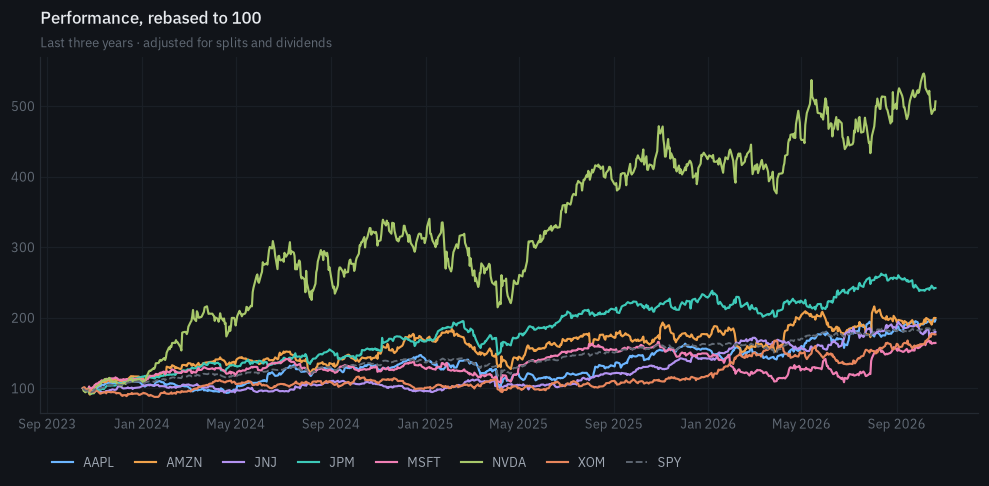

In [3]:
fig, ax = plt.subplots()
perf = F.rebased(prices, start=prices.index[-756])  # last ~3 years
for i, sym in enumerate(c for c in perf.columns if c != BENCHMARK):
    ax.plot(perf.index, perf[sym], label=sym, color=P.SERIES[MODE][i % 8])
ax.plot(perf.index, perf[BENCHMARK], label=BENCHMARK, color=T["text_3"], ls="--", lw=1.2)
P.titles(ax, "Performance, rebased to 100", "Last three years · adjusted for splits and dividends", T)
P.legend_below(ax, 8)
ax.xaxis.set_major_formatter(mdates.DateFormatter("%b %Y"))
plt.show()

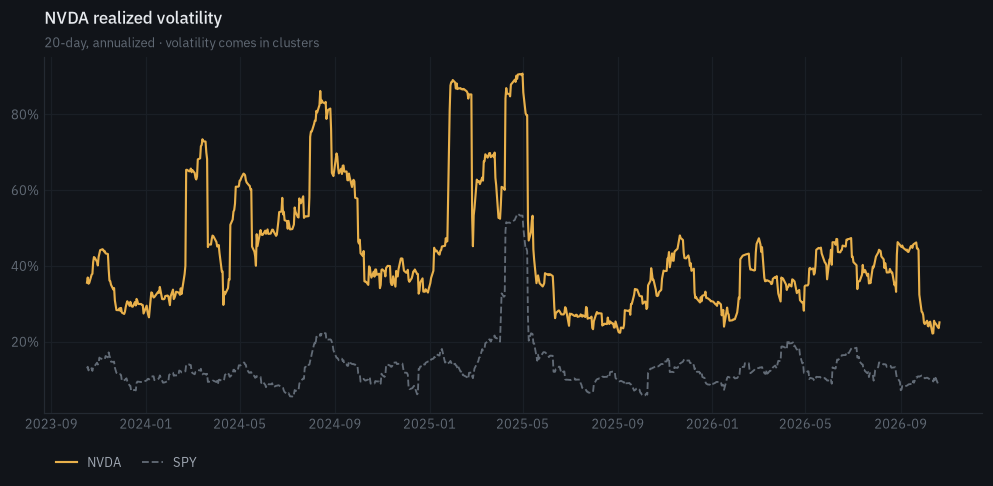

In [4]:
vol = F.realized_vol(returns, window=20)
fig, ax = plt.subplots()
window = vol.index[-756:]
ax.plot(window, vol.loc[window, HIGHLIGHT], color=T["vol"], label=HIGHLIGHT)
ax.plot(window, vol.loc[window, BENCHMARK], color=T["text_3"], ls="--", lw=1.2, label=BENCHMARK)
ax.yaxis.set_major_formatter(PercentFormatter(1.0, decimals=0))
P.titles(ax, f"{HIGHLIGHT} realized volatility", "20-day, annualized · volatility comes in clusters", T)
P.legend_below(ax, 2)
plt.show()

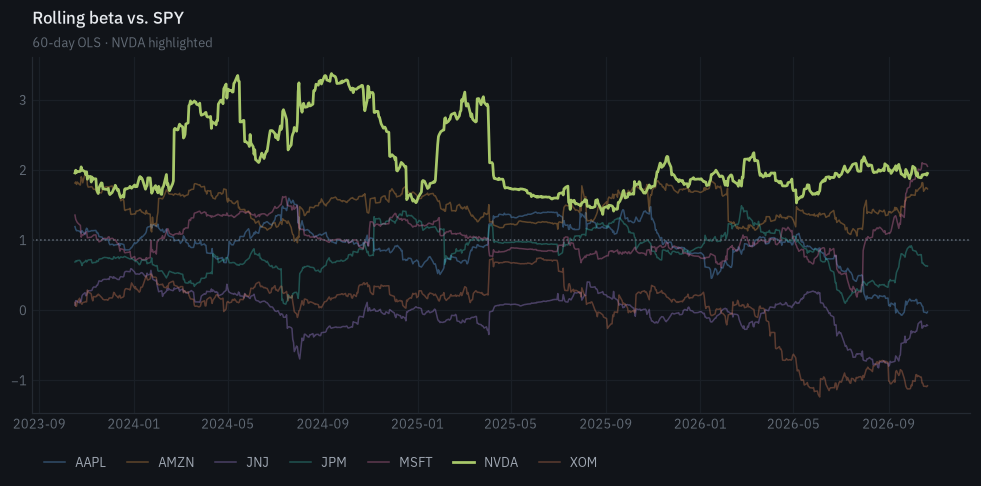

In [5]:
beta = F.rolling_beta(returns, BENCHMARK, window=60)
fig, ax = plt.subplots()
w = beta.index[-756:]
for i, sym in enumerate(beta.columns):
    lw, alpha = (1.8, 1.0) if sym == HIGHLIGHT else (1.0, 0.35)
    ax.plot(w, beta.loc[w, sym], color=P.SERIES[MODE][i % 8], lw=lw, alpha=alpha, label=sym)
ax.axhline(1.0, color=T["text_3"], lw=1, ls=":")
P.titles(ax, f"Rolling beta vs. {BENCHMARK}", f"60-day OLS · {HIGHLIGHT} highlighted", T)
P.legend_below(ax, 7)
plt.show()

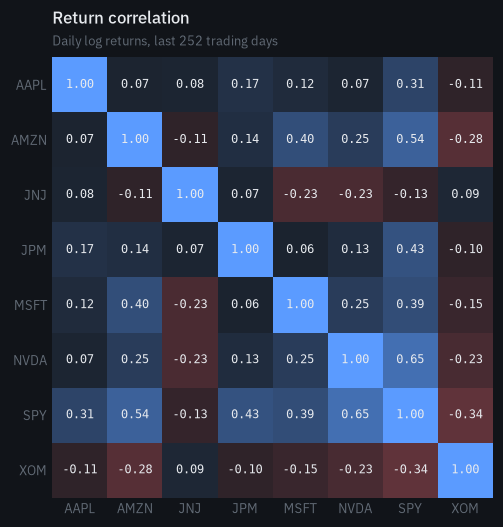

In [6]:
corr = returns.iloc[-252:].corr()
fig, ax = plt.subplots(figsize=(6.2, 5.2))
from matplotlib.colors import LinearSegmentedColormap
cmap = LinearSegmentedColormap.from_list("sw_div", [T["negative"], T["surface_2"], T["accent"]])
im = ax.imshow(corr, cmap=cmap, vmin=-1, vmax=1)
ax.set_xticks(range(len(corr)), corr.columns)
ax.set_yticks(range(len(corr)), corr.index)
ax.grid(False)
for i in range(len(corr)):
    for j in range(len(corr)):
        ax.text(j, i, f"{corr.iloc[i, j]:.2f}", ha="center", va="center", fontsize=8,
                color=T["text_1"], family="monospace")
for s in ax.spines.values():
    s.set_visible(False)
P.titles(ax, "Return correlation", "Daily log returns, last 252 trading days", T)
plt.show()

## Walk-forward backtest

## Backtest

| Model | Center | Range |
|---|---|---|
| `random_walk` | 0 | last 20 days' volatility |
| `drift` | last year's average return | last 20 days' volatility |
| `garch` | constant | GARCH(1,1) with t errors, refit monthly |
| `ets` | AutoETS on log price | its own intervals, refit monthly |

`random_walk` is the baseline everything gets compared to. Takes about a minute.

In [7]:
fc = E.walk_forward(prices, n_origins=504, progress=None)
bt = fc[fc["is_backtest"]]
print(f"{len(fc):,} forecasts · backtest {bt['origin_date'].min().date()} → {bt['origin_date'].max().date()}")

49,128 forecasts · backtest 2024-10-03 → 2026-10-07


## Results

MASE below 1 beats the random walk. Hit rate only means something next to `base_rate`. Coverage should land near 50/80/95. Pinball loss scores the whole range; lower is better.

**Result:** Every model's MASE is between 0.99 and 1.005, which is basically tied with the random walk. Nobody beats `base_rate` on direction. GARCH's hit rate equals it exactly, because its mean is always slightly positive, so it always calls "up." The random walk's 95% band only covers about 92% of outcomes (too narrow), while GARCH sits at 94–95%. GARCH has the lowest pinball loss at 1 and 5 days, and ETS edges it at 10 days.

In [8]:
E.score(fc)

n  mae_bps   mase  hit_rate  base_rate  cov50  cov80  cov95  pinball_bps
model       horizon                                                                             
drift       1        4032  121.672  0.998     0.530      0.538  0.556  0.812  0.924       35.698
            5        4032  286.098  0.996     0.549      0.572  0.504  0.788  0.921       81.340
            10       4032  396.987  1.005     0.537      0.572  0.513  0.787  0.916      112.283
ets         1        4032  121.820  0.999     0.518      0.538  0.610  0.857  0.954       35.707
            5        4032  284.821  0.992     0.556      0.572  0.553  0.831  0.944       80.394
            10       4032  391.533  0.991     0.560      0.572  0.552  0.836  0.944      109.611
garch       1        4032  121.528  0.997     0.538      0.538  0.502  0.800  0.948       34.997
            5        4032  284.262  0.990     0.572      0.572  0.545  0.825  0.946       80.193
            10       4032  392.366  0.993     0.572      0.572  0.557  0.833  0.944      110.697
random_walk 1        4032  121.905  1.000       NaN      0.538  0.549  0.810  0.922       35.693
            5        4032  287.176  1.000       NaN      0.572  0.502  0.781  0.921       81.036
            10       4032  394.971  1.000       NaN      0.572  0.508  0.783  0.924      111.361

Does each model's 1-day range track actual volatility better than trailing 20-day vol? Negative `qlike_vs_rw` means yes.

**Result:** GARCH is best (−0.113), ETS is slightly better than the random walk (−0.041), and drift ties it, since it uses the same volatility.

In [9]:
E.vol_score(fc)

,n,qlike,qlike_vs_rw
model,,,
drift,4032,-7.145,0.000
ets,4032,-7.186,-0.041
garch,4032,-7.257,-0.113
random_walk,4032,-7.145,0.000


Is any improvement more than noise? Diebold-Mariano test against the random walk: a negative stat with p < 0.05 counts as real.

**Result:** Only GARCH at 1 day is significant (stat −5.55, p ≈ 0.00000003). At 5 and 10 days, nothing is distinguishable from the random walk.

In [10]:
pd.DataFrame([E.diebold_mariano(fc, model, horizon=h)
              for model in ("drift", "garch", "ets") for h in E.HORIZONS]).set_index(["model", "horizon"])

loss  n_dates  mean_diff_bps  dm_stat    p_value
model horizon                                                     
drift 1        pinball      504          0.005    0.094  9.252e-01
      5        pinball      504          0.304    0.681  4.960e-01
      10       pinball      504          0.922    0.830  4.067e-01
garch 1        pinball      504         -0.696   -5.553  2.800e-08
      5        pinball      504         -0.843   -1.167  2.431e-01
      10       pinball      504         -0.664   -0.352  7.246e-01
ets   1        pinball      504          0.014    0.065  9.480e-01
      5        pinball      504         -0.642   -1.028  3.038e-01
      10       pinball      504         -1.750   -1.294  1.956e-01

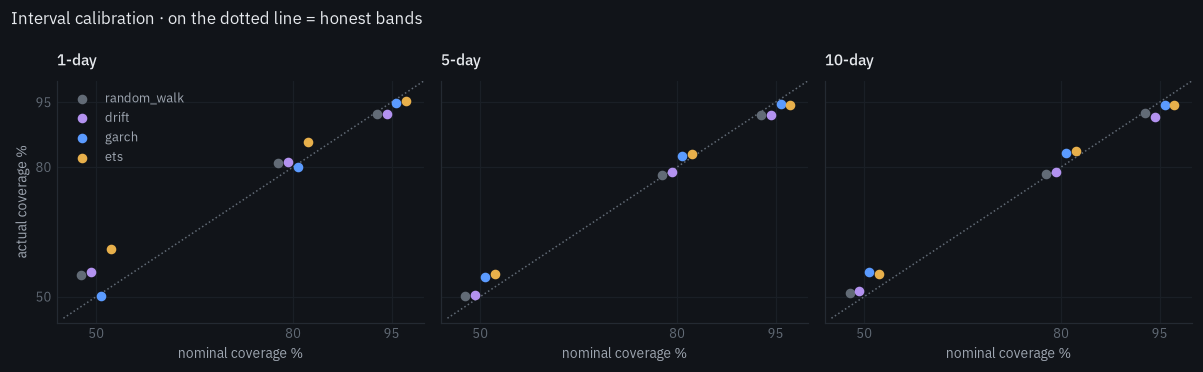

In [11]:
cov = E.score(fc)[["cov50", "cov80", "cov95"]]
fig, axes = plt.subplots(1, 3, figsize=(11, 3.4), sharey=True)
colors = {"random_walk": T["text_3"], "drift": T["violet"], "garch": T["accent"], "ets": T["vol"]}
for ax, h in zip(axes, E.HORIZONS):
    for k, (model, color) in enumerate(colors.items()):
        y = cov.loc[(model, h)].to_numpy()
        ax.scatter([50 + k * 1.5 - 2.25, 80 + k * 1.5 - 2.25, 95 + k * 1.5 - 2.25], y * 100,
                   color=color, s=28, label=model if h == 1 else None, zorder=3)
    ax.plot([45, 100], [45, 100], color=T["text_3"], lw=1, ls=":")
    ax.set_xlim(44, 100); ax.set_ylim(44, 100)
    ax.set_xticks([50, 80, 95]); ax.set_yticks([50, 80, 95])
    ax.set_title(f"{h}-day", fontsize=10)
    ax.set_xlabel("nominal coverage %")
axes[0].set_ylabel("actual coverage %")
axes[0].legend(loc="upper left")
fig.suptitle("Interval calibration · on the dotted line = honest bands", x=0.01, ha="left",
             color=T["text_1"], fontsize=11)
fig.tight_layout()
plt.show()

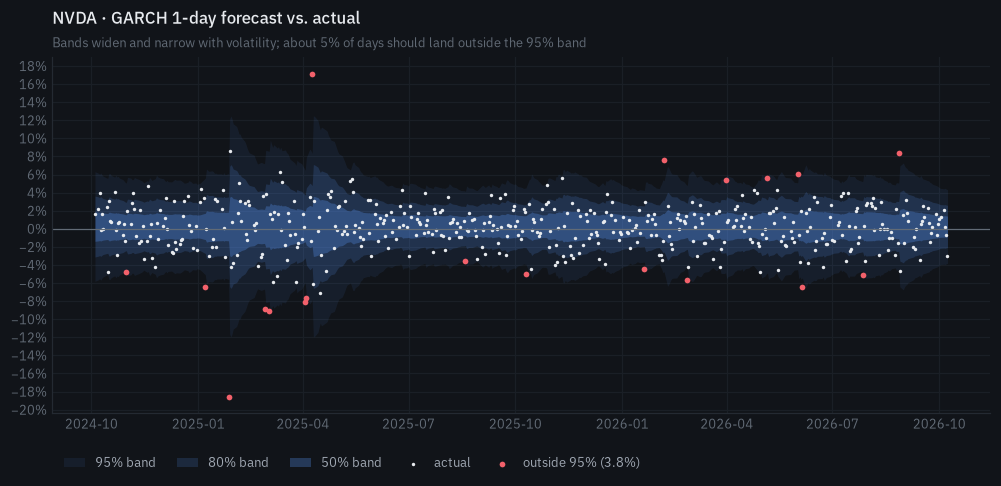

In [12]:
one = fc[(fc["symbol"] == HIGHLIGHT) & (fc["model"] == "garch") & (fc["horizon"] == 1) & fc["is_backtest"]]
one = one.set_index("target_date").sort_index()
fig, ax = plt.subplots()
for level, (lo, hi) in sorted(M.BANDS.items(), reverse=True):
    ax.fill_between(one.index, one[lo], one[hi], color=T["accent"], alpha=P.BAND_ALPHA[level],
                    lw=0, label=f"{level}% band")
inside = (one["actual"] >= one["q025"]) & (one["actual"] <= one["q975"])
ax.scatter(one.index[inside], one["actual"][inside], s=5, color=T["text_1"], lw=0, label="actual")
ax.scatter(one.index[~inside], one["actual"][~inside], s=14, color=T["negative"], lw=0,
           label=f"outside 95% ({(~inside).mean():.1%})")
ax.axhline(0, color=T["text_3"], lw=0.8)
ax.yaxis.set_major_locator(MultipleLocator(0.02))
ax.yaxis.set_major_formatter(PercentFormatter(1.0, decimals=0))
P.titles(ax, f"{HIGHLIGHT} · GARCH 1-day forecast vs. actual",
         "Bands widen and narrow with volatility; about 5% of days should land outside the 95% band", T)
P.legend_below(ax, 5)
plt.show()

##  Forward look

GARCH's 10-day range from the latest close.

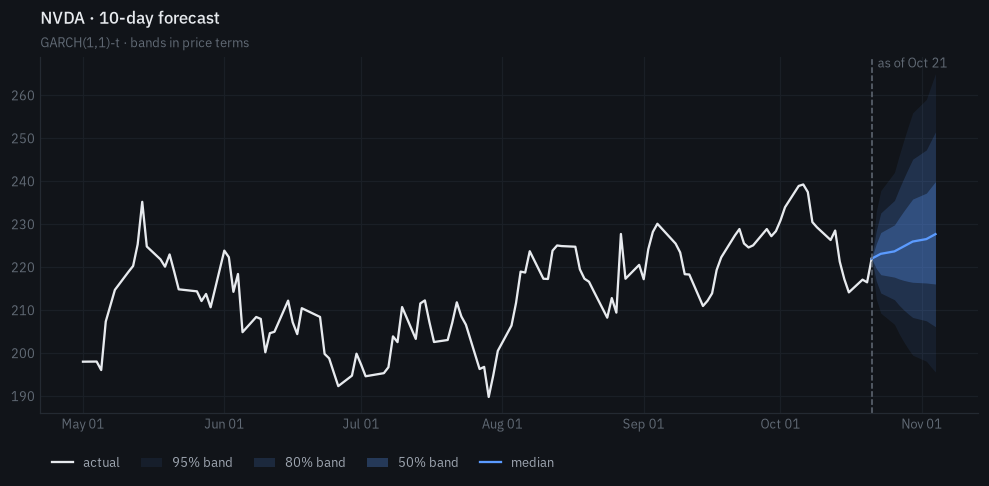

,date,q025,q10,q50,q90,q975
0,2026-10-22,212.64,216.80,222.53,228.42,232.89
1,2026-10-23,209.29,213.97,223.10,232.62,237.82
2,2026-10-26,206.69,212.42,223.67,235.52,242.04
3,2026-10-27,204.54,211.16,224.24,238.13,245.83
4,2026-10-28,202.68,210.08,224.81,240.57,249.36
5,2026-10-29,201.02,209.14,225.38,242.89,252.70
6,2026-10-30,199.50,208.29,225.95,245.12,255.92
7,2026-11-02,198.10,207.52,226.53,247.29,259.03
8,2026-11-03,196.80,206.81,227.11,249.40,262.08
9,2026-11-04,195.58,206.15,227.68,251.47,265.06


In [13]:
r = np.log(prices[HIGHLIGHT].dropna()).diff().dropna()
last = len(r) - 1
fwd = M.garch(r, [last], horizons=range(1, 11))
p0 = prices[HIGHLIGHT].dropna().iloc[-1]
d0 = r.index[-1]
fdates = [d0] + [d0 + pd.offsets.BDay(h) for h in range(1, 11)]
px = {c: np.r_[p0, p0 * np.exp(fwd[c].to_numpy())] for c in M.QCOLS}

hist = prices[HIGHLIGHT].dropna().iloc[-120:]
fig, ax = plt.subplots()
ax.plot(hist.index, hist, color=T["text_1"], lw=1.5, label="actual")
for level, (lo, hi) in sorted(M.BANDS.items(), reverse=True):
    ax.fill_between(fdates, px[lo], px[hi], color=T["accent"], alpha=P.BAND_ALPHA[level], lw=0,
                    label=f"{level}% band")
ax.plot(fdates, px["q50"], color=T["accent"], lw=1.5, label="median")
ax.axvline(d0, color=T["text_3"], lw=1, ls="--")
ax.text(d0, ax.get_ylim()[1], f"  as of {d0:%b %d}", color=T["text_3"], fontsize=8.5, va="top")
ax.xaxis.set_major_formatter(mdates.DateFormatter("%b %d"))
P.titles(ax, f"{HIGHLIGHT} · 10-day forecast", "GARCH(1,1)-t · bands in price terms", T)
P.legend_below(ax, 5)
plt.show()

table = pd.DataFrame({"date": [d.date() for d in fdates[1:]],
                      **{c: px[c][1:] for c in ("q025", "q10", "q50", "q90", "q975")}})
table.round(2)

## Notes

- Direction and point forecasts: no edge over a random walk, as expected.
- The real gain is 1-day volatility: GARCH’s bands are better calibrated, and the improvement is statistically significant. That edge fades by 5 and 10 days.